#**TP 2 - Modelagem Preditiva e Construção de Agentes de IA**

## Imports

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

## Preparação dos dados e pipeline

In [27]:
rng = np.random.default_rng(7)
n = 12000

plano = rng.choice(["basico", "padrao", "premium"], size=n, p=[0.4, 0.4, 0.2])
metodo_pagamento = rng.choice(["cartao_credito", "boleto", "pix"], size=n, p=[0.55, 0.20, 0.25])
dispositivo_principal = rng.choice(["smart_tv", "celular", "computador", "tablet"], size=n, p=[0.35, 0.35, 0.20, 0.10])
tempo_assinatura_meses = np.round(np.clip(rng.exponential(scale=14, size=n), 0, 72), 1)
uso_medio_semanal_horas = np.round(np.clip(rng.normal(9, 4, n), 0, 40), 1)
numero_reclamacoes = rng.poisson(0.4, n)

# churn: menor tempo de assinatura, menor uso e mais reclamações aumentam a chance de cancelar
logit_churn = (
    -0.85
    - 0.04 * tempo_assinatura_meses
    - 0.06 * uso_medio_semanal_horas
    + 0.5 * numero_reclamacoes
    + rng.normal(0, 0.6, n)
)
prob_churn = 1 / (1 + np.exp(-logit_churn))
churn = (rng.uniform(0, 1, n) < prob_churn).astype(int)

# ltv_alto: assinantes de alto valor formam uma região (não um corte linear simples) no espaço
# tempo_assinatura x uso_medio_semanal, com alguma sobreposição de classes nas bordas
raio = np.sqrt(((tempo_assinatura_meses - 40) / 20) ** 2 + ((uso_medio_semanal_horas - 14) / 8) ** 2)
ltv_alto = (raio < 1.0).astype(int)
inverter = rng.random(n) < 0.05
ltv_alto = np.where(inverter, 1 - ltv_alto, ltv_alto)

df = pd.DataFrame({
    "cliente_id": [f"AST-{i:05d}" for i in range(1, n + 1)],
    "plano": plano,
    "metodo_pagamento": metodo_pagamento,
    "dispositivo_principal": dispositivo_principal,
    "tempo_assinatura_meses": tempo_assinatura_meses,
    "uso_medio_semanal_horas": uso_medio_semanal_horas,
    "numero_reclamacoes": numero_reclamacoes,
    "churn": churn,
    "ltv_alto": ltv_alto,
})

df.to_csv("assinantes_neostream.csv", index=False)

In [28]:
%%writefile pipeline_final_churn.py
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Carregamento dos dados e divisão estratificada em treino e teste
df = pd.read_csv("assinantes_neostream.csv")

colunas_numericas = ["tempo_assinatura_meses", "uso_medio_semanal_horas", "numero_reclamacoes"]
colunas_categoricas = ["plano", "metodo_pagamento", "dispositivo_principal"]

X, y = df[colunas_numericas + colunas_categoricas], df["churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, stratify = y, random_state = 42
)

# Pré-processamento: padronização das numéricas e one-hot das categóricas
preprocessador = ColumnTransformer(
    transformers = [
        ("numericas", StandardScaler(), colunas_numericas),
        ("categoricas", OneHotEncoder(handle_unknown = "ignore"), colunas_categoricas),
    ]
)

# Pipeline: pré-processamento + classificador em um único objeto
pipeline = Pipeline(
    steps = [
        ("preprocessamento", preprocessador),
        ("classificador", LogisticRegression()),
    ]
)

# Busca em grade do hiperparâmetro C, com validação cruzada sobre o Pipeline inteiro
grade_c = {"classificador__C": [0.01, 0.1, 1, 10, 100]}
busca = GridSearchCV(pipeline, param_grid = grade_c, cv = 5, scoring = "roc_auc")
busca.fit(X_train, y_train)

# Pipeline final: melhores hiperparâmetros, treinado sobre todo o X_train
pipeline_final = pipeline.set_params(**busca.best_params_)
pipeline_final.fit(X_train, y_train)

print(f"Melhores hiperparâmetros: {busca.best_params_}")
print(f"ROC AUC médio na validação cruzada: {busca.best_score_:.4f}")
print(f"ROC AUC no teste: {roc_auc_score(y_test, pipeline_final.predict_proba(X_test)[:, 1]):.4f}")

Writing pipeline_final_churn.py


In [29]:
%run pipeline_final_churn.py

Melhores hiperparâmetros: {'classificador__C': 0.01}
ROC AUC médio na validação cruzada: 0.6578
ROC AUC no teste: 0.6640


<Figure size 640x480 with 0 Axes>

## **EXERCÍCIO 1**

### 1.1 Gere as previsões do Pipeline do TP1 para X_test e construa a matriz de confusão com confusion_matrix(y_test, y_pred).

In [30]:
y_pred = pipeline_final.predict(X_test)
matriz_confusao = confusion_matrix(y_test, y_pred)

pd.DataFrame(
    matriz_confusao,
    index = ["real: não churn (0)", "real: churn (1)"],
    columns = ["previsto: não churn (0)", "previsto: churn (1)"],
)

,previsto: não churn (0),previsto: churn (1)
real: não churn (0),1978,1
real: churn (1),419,2


A análise do pipeline treinado no TP1 foi feita usando as previsões geradas com `pipeline_final.predict(X_test)`, e depois foi construida uma matriz de confusão com `confusion_matrix(y_test, y_pred)`.

### 1.2 Identifique explicitamente, a partir da matriz, os valores de verdadeiros positivos, falsos positivos, verdadeiros negativos e falsos negativos.

In [32]:
tn, fp, fn, tp = matriz_confusao.ravel()

print(f"Verdadeiros negativos (TN): {tn}")
print(f"Falsos positivos (FP): {fp}")
print(f"Falsos negativos (FN): {fn}")
print(f"Verdadeiros positivos (TP): {tp}")

Verdadeiros negativos (TN): 1978
Falsos positivos (FP): 1
Falsos negativos (FN): 419
Verdadeiros positivos (TP): 2


Considerando o churn como classe positiva, o modelo teve 1978 verdadeiros negativos, 1 falso positivo, 419 falsos negativos e 2 verdadeiros positivos.

### 1.3 Escreva em um bloco de texto intitulado ANALISE DA MATRIZ DE CONFUSAO o que cada célula representa em termos de negócio: por exemplo, o custo de um falso negativo (assinante que cancela sem alerta prévio).

**Análise da Matriz de Confusão**
- **Verdadeiros negativos (1978):** são assinantes que ficaram e o modelo sinalizou corretamente que eles ficaram. Eles não geram custo, já que a equipe de retenção não precisa agir sobre eles.
- **Falsos positivos (1):** são assinantes que não iriam sair, mas o modelo classificou como risco de churn. Eles geram um custo, já que a equipe de retenção se dedica a reter ele sem ter nescessidade.
- **Falsos negativos (419):** são assinantes que o modelo previu que não iriam cancelar, mas cancelaram. É o pior erro da matriz nesse cenário, já que a empresa perde assinantes sem ter a chance de tentar retê-los.
- **Verdadeiros positivos (2):** são assinantes que iriam cancelar e foram corretamentes sinalizados pelo modelo. Esses são os clientes em que a camapanha busca encontrar para ter a chance de reter eles e evitar o churn.

**Resposta ao tech lead:**  da forma que esta, o modelo deixa passar quase todos os cancelamentos, e quase não gera alarmes falsos. O modelo emitiu 3 alertas de churn, e 2 deles estavam certos, ou seja, os alertas são confiáveis, mas não combrem quase nada, já que deixaram passar 419 casos que deveriam ser alertados, não servindo para orientar uma campanha de retenção.

## **EXERCÍCIO 2**

### 2.1 Calcule precision_score e recall_score do Pipeline do TP1 usando o threshold padrão de 0.5 sobre predict_proba.

In [33]:
y_proba = pipeline_final.predict_proba(X_test)[:, 1]

def calcular_precisao_recall(y_true, y_proba, threshold):
    y_pred_limiar = (y_proba >= threshold).astype(int)
    return precision_score(y_true, y_pred_limiar, zero_division = 0), recall_score(y_true, y_pred_limiar)

precisao_05, recall_05 = calcular_precisao_recall(y_test, y_proba, 0.5)

print(f"Precisão (threshold 0.5): {precisao_05:.2%}")
print(f"Recall (threshold 0.5): {recall_05:.2%}")

Precisão (threshold 0.5): 66.67%
Recall (threshold 0.5): 0.48%


A probabilidade do churn foi obtida usando o `predict_proba`, e usando a threshold de 0,5, a precisão foi de 66.68% e o recall de 0,48%, o que é coerente com os resultados obtidos no exercício anterior.

### 2.2 Recalcule precisão e recall para pelo menos três thresholds diferentes (por exemplo, 0.3, 0.5, 0.7) aplicados manualmente sobre predict_proba.

In [34]:
limiares = [0.05, 0.1, 0.2, 0.3, 0.5, 0.7]

resultados_limiares = pd.DataFrame(
    [
        (limiar, (y_proba >= limiar).sum(), *calcular_precisao_recall(y_test, y_proba, limiar))
        for limiar in limiares
    ],
    columns = ["threshold", "alertas", "precisao", "recall"],
)

resultados_limiares.style.format({"precisao": "{:.2%}", "recall": "{:.2%}"})

,threshold,alertas,precisao,recall
0,0.050000,2300,18.13%,99.05%
1,0.100000,2008,19.77%,94.30%
2,0.200000,789,26.36%,49.41%
3,0.300000,190,35.79%,16.15%
4,0.500000,3,66.67%,0.48%
5,0.700000,0,0.00%,0.00%


A precisão e o recall foram recalculados usando os thresholds 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, aplicados manualmente sobre `predict_proba`. Observando a tabela formada, nota-se que a medida que o threshold diminui, o recall sobe e a precisão cai, uma vez que flexibilizamos quando o modelo deve sinalizar um cliente.

### 2.3 Registre os resultados em uma tabela em um bloco de texto intitulado TRADEOFF PRECISAO-RECALL e recomende, por escrito, qual threshold usar se a empresa priorizar não perder nenhum assinante em risco de churn.

**Tradeoff Precisão-Recall**

| threshold | alertas (de 2400) | precisão | recall |
|---|---|---|---|
| 0.05 | 2300 | 18,13% | 99,05% |
| 0.10 | 2008 | 19,77% | 94,30% |
| 0.20 | 789 | 26,36% | 49,41% |
| 0.30 | 190 | 35,79% | 16,15% |
| 0.50 | 3 | 66,67% | 0,48% |
| 0.70 | 0 | 0% (sem alertas) | 0,00% |

**Leitura:** quanto menor o threshold, maior a flexibilização de probabilidade para o modelo sinalizar um cliente, o que quer dizer que o recall vai ser mais alto e a precisão mais baixa, já que o modelo vai sinalizar mais pessoas, evitando falsos negativos, mas mais clientes sinalizados serão falsos positivos. Para escolher um threshold adequado, deve se procurar um equilibrio entre precisão e recall, considerando o que é mais relevante para a análise.

**Recomendação para priorizar não perder nenhum assinante em risco:** se a prioridade da empresa é não perder nenhum assinante em risco, deve se usar o menor threshold testado, de 0,05, que irá captar 99,05% dos clientes que iriam cancelar, porém o custo é alto, já que a baixa precisão indica que a maior parte dos alertas são desnecessários, de clientes que não iriam cancelar, gerando um custo indevido.

## **EXERCÍCIO 3**

### 3.1 Calcule a curva ROC e o roc_auc_score para o Pipeline do TP1 sobre X_test.

In [35]:
fpr, tpr, _ = roc_curve(y_test, y_proba)
auc_teste = roc_auc_score(y_test, y_proba)

print(f"Pontos na curva ROC: {len(fpr)}")
print(f"ROC AUC no teste: {auc_teste:.4f}")

Pontos na curva ROC: 662
ROC AUC no teste: 0.6640


A curva ROC foi calculada usando `roc_curve(y_test, y_proba)`, que retorna a taxa de falsos positivos e de verdadeiros positos para cada threshold possível, eunquanto `roc_auc_score(y_test, y_proba)` resume a curva em um único número.

### 3.2 Plote a curva ROC com RocCurveDisplay.

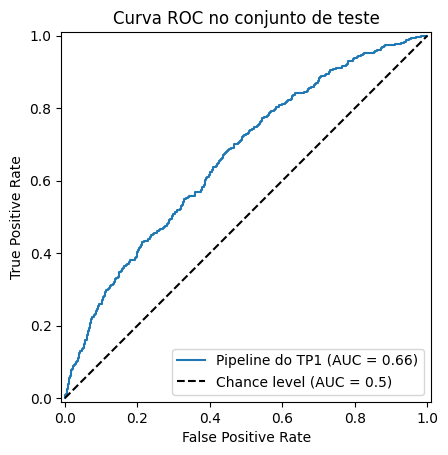

In [36]:
RocCurveDisplay(fpr = fpr, tpr = tpr, roc_auc = auc_teste).plot(plot_chance_level = True, name = "Pipeline do TP1")

plt.title("Curva ROC no conjunto de teste")
plt.show()
plt.show()

A curva do modelo fica acima da linha tracejada, que representa um classificador aleatório, demostrando que o modelo de fato classifica o churn melhor que a sorte, porém, como ainda está muito próximo da linha diagonal, e distante do canto superior esquerdo, que representa o menor cenário, é claro que o modelo não tem uma ótimo eficiência.

### 3.3 Escreva em um bloco de texto intitulado COMPARACAO AUC-ROC uma justificativa técnica de por que AUC-ROC é adequada para comparar classificadores antes da escolha final de threshold.

**Comparação AUC-ROC**

A AUR-ROC é adequada para comparar classificadores antes da escolha final de threshold pois não depende de um limiar fixo, ela percorre todos os threasholds possiveis e resume visualmente o desempenho de cada um deles, facilitando o momento da escolha.

## **EXERCÍCIO 4**

### 4.1 Extraia os coeficientes (coef_) e o intercepto (intercept_) do LogisticRegression treinado no TP1.

In [37]:
preprocessamento = pipeline_final.named_steps["preprocessamento"]
classificador = pipeline_final.named_steps["classificador"]

coeficientes = pd.Series(classificador.coef_[0], index = preprocessamento.get_feature_names_out())
intercepto = classificador.intercept_[0]

print(f"Intercepto: {intercepto:.4f}")
coeficientes

Intercepto: -1.6503


,0
numericas__tempo_assinatura_meses,-0.480257
numericas__uso_medio_semanal_horas,-0.203423
numericas__numero_reclamacoes,0.310984
categoricas__plano_basico,0.015854
categoricas__plano_padrao,0.030924
categoricas__plano_premium,-0.047528
categoricas__metodo_pagamento_boleto,0.021475
categoricas__metodo_pagamento_cartao_credito,-0.023436
categoricas__metodo_pagamento_pix,0.001210
categoricas__dispositivo_principal_celular,-0.018172


Foram extraídos 13 coeficientes, um para cada coluna gerada pelo `ColumnTransformer`, além de um intercepto de -1,6503.

### 4.2 Calcule manualmente, para três assinantes de X_test, a combinação linear das features e aplique a função sigmoid para obter a probabilidade de churn.

In [38]:
assinantes = X_test.iloc[:3]
display(assinantes)

features_transformadas = preprocessamento.transform(assinantes)

z = features_transformadas @ coeficientes.values + intercepto
probabilidade_manual = 1 / (1 + np.exp(-z))

pd.DataFrame(
    {"z (combinação linear)": z, "probabilidade (sigmoid)": probabilidade_manual},
    index = assinantes.index,
).style.format("{:.4f}")

,tempo_assinatura_meses,uso_medio_semanal_horas,numero_reclamacoes,plano,metodo_pagamento,dispositivo_principal
5924,3.4,9.9,0,basico,cartao_credito,celular
7890,4.3,12.2,1,basico,boleto,celular
1619,2.0,5.5,1,padrao,cartao_credito,computador


,z (combinação linear),probabilidade (sigmoid)
5924,-1.5470,0.1755
7890,-1.1546,0.2397
1619,-0.7053,0.3306


Para os três primeiros assinantes de `X_test`, as features foram transformadas pelo `ColumnTransformer`. Após isso, foi calculado manualmente a combinação linear `z = intercepto + soma(coeficiente × feature)` e aplicado a função sigmoid `1 / (1 + e^(-z))`. Os três valores de z ficaram negativos, o que pela sigmoid resulta em probabilidades abaixo de 0,5, no caso 17,55%, 23,97% e 33,06%.

### 4.3 Compare os valores calculados manualmente com a saída de predict_proba para os mesmos três assinantes e registre a comparação em um bloco de texto intitulado DEMONSTRACAO SIGMOIDE.

In [39]:
probabilidade_predict_proba = pipeline_final.predict_proba(assinantes)[:, 1]

comparacao_sigmoide = pd.DataFrame(
    {
        "manual": probabilidade_manual,
        "predict_proba": probabilidade_predict_proba,
        "diferenca_absoluta": abs(probabilidade_manual - probabilidade_predict_proba),
    },
    index = assinantes.index,
)

print(f"Valores iguais (np.allclose): {np.allclose(probabilidade_manual, probabilidade_predict_proba)}")
comparacao_sigmoide.style.format("{:.6f}")

Valores iguais (np.allclose): True


,manual,predict_proba,diferenca_absoluta
5924,0.175522,0.175522,0.000000
7890,0.239651,0.239651,0.000000
1619,0.330648,0.330648,0.000000


**Demonstração Sigmoide**

| assinante (índice) | z | probabilidade manual | `predict_proba` |
|---|---|---|---|
| 5924 | -1,5470 | 0,175522 | 0,175522 |
| 7890 | -1,1546 | 0,239651 | 0,239651 |
| 1619 | -0,7053 | 0,330648 | 0,330648 |

Os valores calculados manualmente são iguais aos dados pelo uso de `predict_proba`. Demostrando como o modelo funciona, o `ColumnTransformer` converte o assinante em 13 números, o `LogisticRegression` calcula `z` através de uma combinação linear desses números com os coeficientes e o intercepto, e por fim a função sigmoid converte `z` em um valor entre 0 e 1, interpretado como probabilidade de churn.

## **EXERCÍCIO 5**

### 5.1 Use a coluna plano como variável alvo (três categorias) e treine um LogisticRegression sobre as mesmas features numéricas do TP1 (sem incluir plano entre as features, apenas como alvo).

In [40]:
modelo_plano = Pipeline(
    steps = [
        ("padronizacao", StandardScaler()),
        ("classificador", LogisticRegression()),
    ]
)

modelo_plano.fit(X_train[colunas_numericas], X_train["plano"])

Pipeline(steps=[('padronizacao', StandardScaler()),
                ('classificador', LogisticRegression())])

### 5.2 Avalie a acurácia por classe com classification_report e identifique a classe com pior desempenho.

In [41]:
y_pred_plano = modelo_plano.predict(X_test[colunas_numericas])

print(classification_report(X_test["plano"], y_pred_plano, zero_division = 0))
print(pd.Series(y_pred_plano).value_counts())

              precision    recall  f1-score   support

      basico       0.41      0.83      0.55       991
      padrao       0.39      0.16      0.23       913
     premium       0.00      0.00      0.00       496

    accuracy                           0.41      2400
   macro avg       0.26      0.33      0.26      2400
weighted avg       0.32      0.41      0.31      2400

basico    2021
padrao     379
Name: count, dtype: int64


A classe com o pior desempenho foi a premium, em que a acurácia geral é de 41%, com uma proporção praticamente igual da maior classe do teste, ou seja, o resultado é parecido com o de um modelo que sempre prevê `basico`. Além disso, o modelo previu apenas `basico` e `padrao`, o que indica que o tempo de assinatura, uso e reclamações trazem pouca informação para distinguir o plano do assinante.

### 5.3 Explique em um bloco de texto intitulado REGRESSAO LOGISTICA MULTICLASSE como a função softmax generaliza a sigmoid binária para o caso de três classes.

**Regressão Logistica Multiclasse**

Na regressão logística binária, o modelo calcula uma pontuação `z` que é convertida pela função sigmoid na probabilidade da classe positiva, $p = \frac{1}{1 + e^{-z}}$, e a outra classe fica com $1 - p$.

Com três classes, `basico`, `padrao` e `premium`, o modelo aprende um conjunto de coeficientes para cada classe e calcula uma pontuação $z_k = b_k + w_k \cdot x$ para cada uma delas.

A função softmax generaliza a sigmoid ao transformar essas três pontuações em probabilidades, ou seja:

$$P(\text{classe } k) = \frac{e^{z_k}}{e^{z_1} + e^{z_2} + e^{z_3}}$$

A softmax devolve valores entre 0 e 1, e a pontuação maior resulta em uma probabilidade maior. Ao contrário da sigmoid, em vez de comparar uma classe com o seu complemento, ela compara todas as classes entre si, e as três probabilidades somam 1, com a classe prevista sendoa de maior probabilidade.

## **EXERCÍCIO 6**

### 6.1 Gere curvas de aprendizado (learning_curve) para o LogisticRegression do TP1 com pelo menos três valores diferentes do parâmetro C (inverso da regularização Ridge).

In [42]:
valores_c = [0.001, 0.01, 1, 100]
curvas_aprendizado = {}

for c in valores_c:
    pipeline_c = clone(pipeline_final).set_params(classificador__C = c)
    tamanhos_treino, scores_treino, scores_validacao = learning_curve(
        pipeline_c, X_train, y_train, train_sizes = np.linspace(0.1, 1.0, 5), cv = 5, scoring = "roc_auc"
    )
    curvas_aprendizado[c] = (scores_treino, scores_validacao)

resumo_curvas = pd.DataFrame(
    {
        "auc_treino": [curvas_aprendizado[c][0][-1].mean() for c in valores_c],
        "auc_validacao": [curvas_aprendizado[c][1][-1].mean() for c in valores_c],
    },
    index = pd.Index(valores_c, name = "C"),
)
resumo_curvas["gap"] = resumo_curvas["auc_treino"] - resumo_curvas["auc_validacao"]

resumo_curvas.style.format("{:.4f}")

,auc_treino,auc_validacao,gap
C,,,
0.001000,0.6594,0.6566,0.0027
0.010000,0.6613,0.6578,0.0035
1.000000,0.6615,0.6574,0.0041
100.000000,0.6615,0.6574,0.0041


Foram geradas curvas de aprendizado usando `learning_curve` com valores de `C`, 0.001, 0.01, 1 e 100. Para cada  um dos valores, a Pipeline é treinada com tamanhos crescentes de conjunto de treino, e avaliado por validação cruzada de 5 dobras. O `clone(pipeline_final).set_params(...)` cria uma cópia sem ajuste do Pipeline com o `C` desejado, e como o pré-processamento está dentro dele, é reajustado em cada subconjunto, sem vazamento.

### 6.2 Plote as curvas de treino e validação para cada valor de C.

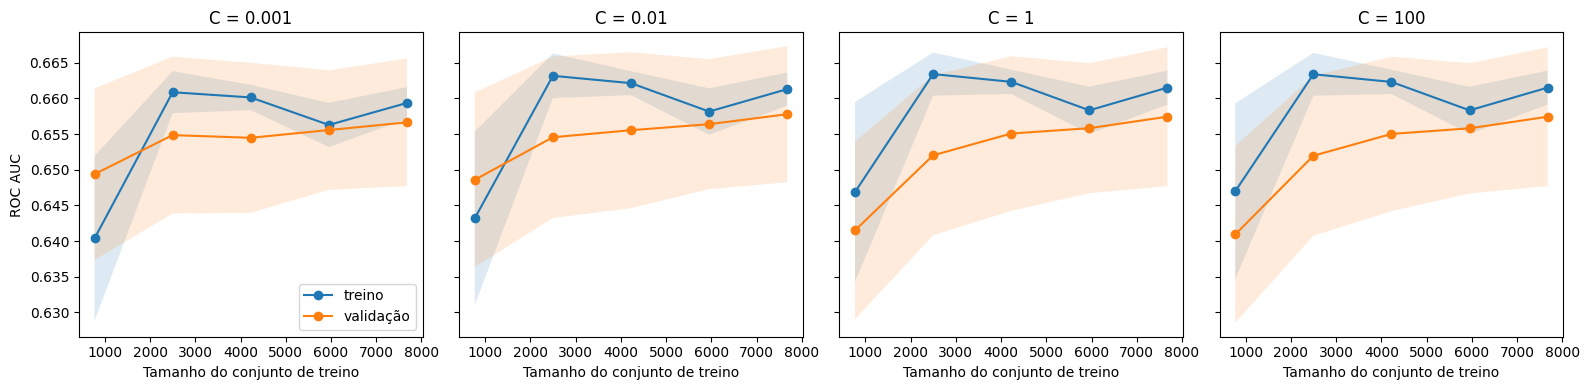

In [43]:
fig, eixos = plt.subplots(1, len(valores_c), figsize = (16, 4), sharey = True)

for eixo, c in zip(eixos, valores_c):
    scores_treino, scores_validacao = curvas_aprendizado[c]
    for scores, rotulo in [(scores_treino, "treino"), (scores_validacao, "validação")]:
        media, desvio = scores.mean(axis = 1), scores.std(axis = 1)
        eixo.plot(tamanhos_treino, media, marker = "o", label = rotulo)
        eixo.fill_between(tamanhos_treino, media - desvio, media + desvio, alpha = 0.15)
    eixo.set_title(f"C = {c}")
    eixo.set_xlabel("Tamanho do conjunto de treino")

eixos[0].set_ylabel("ROC AUC")
eixos[0].legend()
plt.tight_layout()
plt.show()

Cada gráfico mostra a curva de treino e a de validação para um valor de `C`, e em todos eles, as duas curvas ficam muito próximas. A curva de validação sobe devagar conforme o treino cresce e se aproxima de um patamar nos últimos pontos, enquanto a de treino se estabiliza em torno de 0,66.

### 6.3 Recomende, em um bloco de texto intitulado ANALISE DA REGULARIZACAO RIDGE, qual valor de C reduz o gap entre treino e validação sem prejudicar o desempenho geral.

**Análise da Regularização Ridge**

| C | AUC treino | AUC validação | gap |
|---|---|---|---|
| 0.001 | 0,6594 | 0,6566 | 0,0027 |
| 0.01 | 0,6613 | 0,6578 | 0,0035 |
| 1 | 0,6615 | 0,6574 | 0,0041 |
| 100 | 0,6615 | 0,6574 | 0,0041 |

**Recomendação:** `C = 0.01`, já que entre os valores testados, ele tem a maior AUC de validação e um gap menor que o de `C = 1` e `C = 100`, que se comportam de uma forma idêntica, pois a regularização com `C` alto é fraca demais para fazer diferença.

## **EXERCÍCIO 7**

### 7.1 Treine um SVC(kernel='linear') sobre um subconjunto de duas features numéricas escolhidas para separar ltv_alto de forma aproximadamente linear.

In [44]:
df.groupby("ltv_alto")[colunas_numericas].mean().round(2)

,tempo_assinatura_meses,uso_medio_semanal_horas,numero_reclamacoes
ltv_alto,,,
0,11.20,8.74,0.40
1,27.63,10.58,0.38


In [45]:
colunas_ltv = ["tempo_assinatura_meses", "uso_medio_semanal_horas"]
y_ltv_train = df.loc[X_train.index, "ltv_alto"]
y_ltv_test = df.loc[X_test.index, "ltv_alto"]


def construir_svm(kernel, c):
    return Pipeline(
        steps = [
            ("padronizacao", StandardScaler()),
            ("svc", SVC(kernel = kernel, C = c)),
        ]
    )


modelo_linear = construir_svm("linear", 1).fit(X_train[colunas_ltv], y_ltv_train)
modelo_linear

Pipeline(steps=[('padronizacao', StandardScaler()),
                ('svc', SVC(C=1, kernel='linear'))])

Para escolher as features, foi realizado uma comparação com a média de cada variável numérica entre os assinantes de alto valor e os demais. A variavél `tempo_assinatura_meses` foi a que mais separou os grupos, seguida de `uso_medio_semanal_horas`, enquanto `numero_reclamacoes` é praticamente igual em ambos. Por tanto, foram escolhidas `tempo_assinatura_meses` e `uso_medio_semanal_horas`.

A padronização foi colocada dentro de uma pipeline, junto com o `SVC(kernel = 'linear')`, treinado com o `C = 1` padrão, que é montada pela função `construir_svm`.

### 7.2 Plote a fronteira de decisão e os vetores de suporte (support_vectors_) em um gráfico 2D.

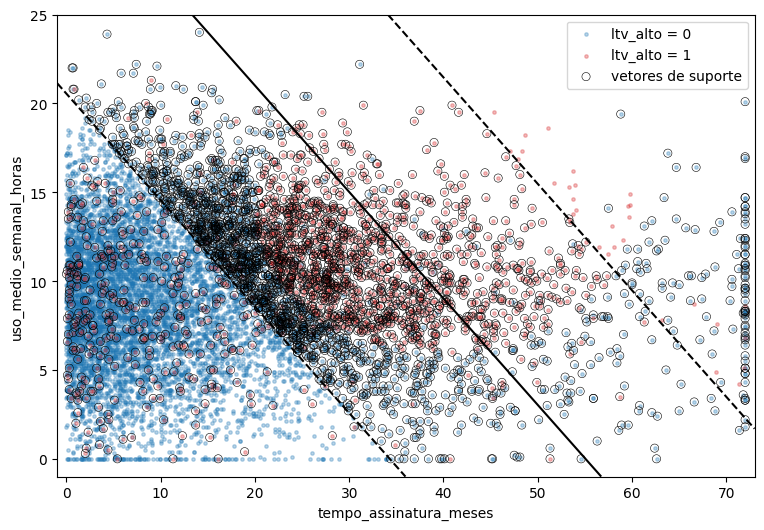

In [46]:
scaler_linear = modelo_linear.named_steps["padronizacao"]
svc_linear = modelo_linear.named_steps["svc"]
vetores_suporte = scaler_linear.inverse_transform(svc_linear.support_vectors_)

fig, eixo = plt.subplots(figsize = (9, 6))

DecisionBoundaryDisplay.from_estimator(
    modelo_linear,
    X_train[colunas_ltv],
    response_method = "decision_function",
    plot_method = "contour",
    levels = [-1, 0, 1],
    colors = "k",
    linestyles = ["--", "-", "--"],
    ax = eixo,
)

for classe, cor in [(0, "tab:blue"), (1, "tab:red")]:
    pertence = y_ltv_train == classe
    eixo.scatter(
        X_train.loc[pertence, colunas_ltv[0]],
        X_train.loc[pertence, colunas_ltv[1]],
        s = 6, alpha = 0.3, color = cor, label = f"ltv_alto = {classe}",
    )

eixo.scatter(
    vetores_suporte[:, 0], vetores_suporte[:, 1],
    s = 35, facecolors = "none", edgecolors = "k", linewidths = 0.4, label = "vetores de suporte",
)
eixo.set_xlabel(colunas_ltv[0])
eixo.set_ylabel(colunas_ltv[1])
eixo.legend(loc = "upper right")
plt.show()

No gráfico, a linha continua representa a fronteira de decisão, a linha tracejada as margens, os circulos os vetores de suporte, e os pontos são os treinos por classe, sendo em vermelho `ltv_alto = 1` e em azul `ltv_alto = 0`.

Os assinantes de alto valor ficaram concentrados a direita da fronteira, e os outros a esquerda, se misturando em uma faixa entre as duas seções.
Dessa forma, uma reta só separa as classes de forma aproximada, e a maioria dos vetores de suporte está nessa faixa de sobreposição.

### 7.3 Explique em um bloco de texto intitulado SVM MARGEM MAXIMA o papel dos vetores de suporte na definição da fronteira, diferente do que ocorre em LogisticRegression.

**SVM Margem Máxima**

Entre todas as retas que separam as classes, o SVA procura qual maximiza a margem, a distância entre a fronteira e os pontos mais próximos de cada classe.

Os pontos mais próximos são chamados de vetores de suporte, e eles tem o objetivo de definir a fronteira, já que a posição e inclinação da reta dependem apenas dos vetores de suporte, e determinar a margem.

Já o `LogisticRegression` considera todos os pontos de treino, e cada um contribui para o cálculo dos coeficientes, inclusive os que estão longe da fronteira. Por isso, mover pontos "fáceis" pode alterar a fronteira da regressão logística, mas não a do SVM.

## **EXERCÍCIO 8**

### 8.1 Treine SVC(kernel='linear') com pelo menos três valores diferentes do parâmetro C (por exemplo, 0.01, 1, 100) sobre o dataset completo de ltv_alto.

In [47]:
valores_c_svm = [0.01, 1, 100]

modelos_lineares = {
    c: construir_svm("linear", c).fit(X_train[colunas_ltv], y_ltv_train) for c in valores_c_svm
}

Foram treinados `SVC(kernel = 'linear')` com os valores de C em 0.01, 1 e 100, com as features `tempo_assinatura_meses` e `uso_medio_semanal_horas` e usando todos os 9600 assinantes do conjunto de treino.

### 8.2 Compare, para cada valor de C, o número de vetores de suporte e a acurácia em X_test.

In [ ]:
comparacao_c = pd.DataFrame(
    {
        "vetores_suporte": [modelos_lineares[c].named_steps["svc"].n_support_.sum() for c in valores_c_svm],
        "acuracia_treino": [accuracy_score(y_ltv_train, modelos_lineares[c].predict(X_train[colunas_ltv])) for c in valores_c_svm],
        "acuracia_teste": [accuracy_score(y_ltv_test, modelos_lineares[c].predict(X_test[colunas_ltv])) for c in valores_c_svm],
    },
    index = pd.Index(valores_c_svm, name = "C"),
)

print(f"Acurácia de sempre prever a classe majoritária (teste): {1 - y_ltv_test.mean():.4f}")
comparacao_c.style.format({"acuracia_treino": "{:.4f}", "acuracia_teste": "{:.4f}"})

Acurácia de sempre prever a classe majoritária (teste): 0.8342


,vetores_suporte,acuracia_treino,acuracia_teste
C,,,
0.010000,3075,0.8460,0.8500
1.000000,3031,0.8539,0.8583
100.000000,3032,0.8538,0.8583


- **Vetores de suporte:** 3075 em `C = 0.01`, 3031 em `C = 1` e 3032 em `C = 100`, a variação é muito pequena, com essa sobreposição de classes, cerca de um terço dos pontos fica na margem ou dentro dela qualquer que seja o `C`.
- **Acurácia no teste:** 85,00% em `C = 0.01` e 85,83% em `C = 1` e `C = 100`, apenas 1,6 a 2,4 pontos percentuais acima da referência.
- **Treino contra teste:** a acurácia de treino foi parecida com a do teste, então não há gap que indique variância alta.

### 8.3 Registre em um bloco de texto intitulado AJUSTE SOFT MARGIN qual valor de C representa o melhor equilíbrio entre bias e variância para este problema, com base nos resultados observados.

**Ajuste Soft Margin**

Com base nos resultados observados, `C = 1` é o melhor equilíbrio entre bias e variância para este problema,

Com `C = 0.01`, a penalidade é muito pequena e a margem fica muito tolerante, o modelo tem a menor acurácia, com 85,00% no teste e 84,60% no treino, e mais vetores de suporte, o que é sinal de bias um pouco maior.

Usando `C = 100`, a acurácia é idêntica à de `C = 1`, com 85,83% no teste, mas o modelo não ganha nada em troca de um treino que é cerca de 40 vezes mais lento e uma rigidez que aumentaria o risco de variância em dados com sobreposição de classes.

Já com `C = 1`, a acurácia é a mais alta do grupo, com tolerância moderada às exceções, e o treino é rápido.

## **EXERCÍCIO 9**

### 9.1 Treine SVC(kernel='rbf') sobre o mesmo dataset de ltv_alto do Exercício 8, usando o melhor valor de C encontrado.

In [48]:
melhor_c = 1

modelo_rbf = construir_svm("rbf", melhor_c).fit(X_train[colunas_ltv], y_ltv_train)
modelo_rbf

Pipeline(steps=[('padronizacao', StandardScaler()), ('svc', SVC(C=1))])

Foi treinado um `SVC(kernel = 'rbf')` com o mesmo dataset de `ltv_alto` usado anteriormente e com o melhor valor de `C` encontrado, `C = 1`.

### 9.2 Compare a acurácia e a fronteira de decisão do kernel RBF com as do kernel linear do Exercício 8, plotando as visualizações lado a lado.

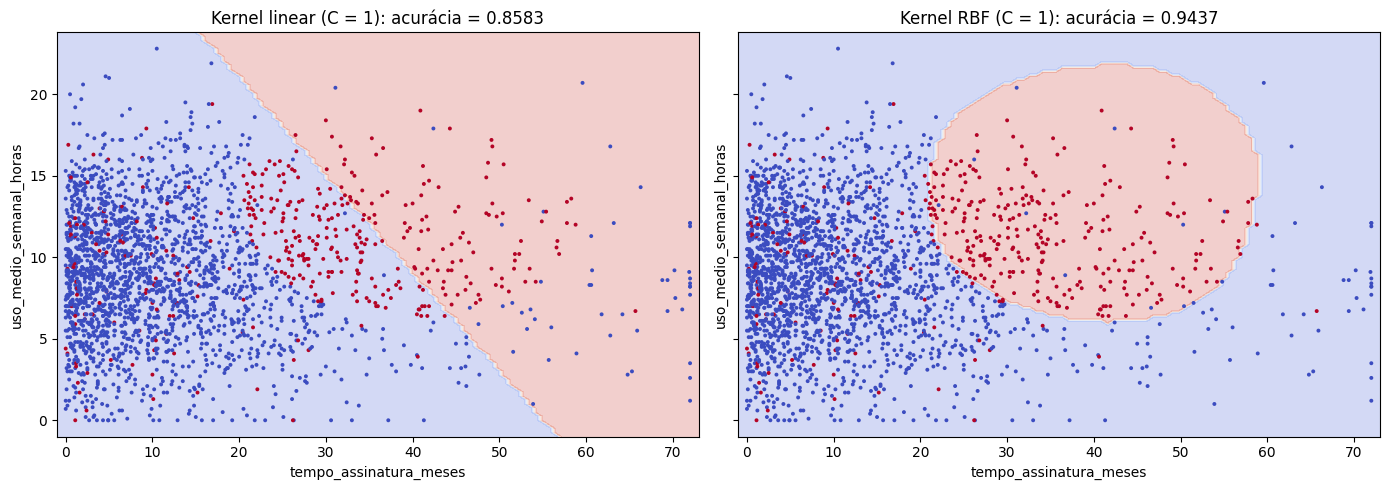

In [49]:
modelos_comparacao = {"Kernel linear": modelos_lineares[melhor_c], "Kernel RBF": modelo_rbf}

fig, eixos = plt.subplots(1, 2, figsize = (14, 5), sharey = True)

for eixo, (nome, modelo) in zip(eixos, modelos_comparacao.items()):
    acuracia = accuracy_score(y_ltv_test, modelo.predict(X_test[colunas_ltv]))
    DecisionBoundaryDisplay.from_estimator(
        modelo, X_test[colunas_ltv], response_method = "predict", cmap = "coolwarm", alpha = 0.25, ax = eixo
    )
    eixo.scatter(
        X_test[colunas_ltv[0]], X_test[colunas_ltv[1]], c = y_ltv_test, cmap = "coolwarm", s = 8, edgecolors = "none"
    )
    eixo.set_title(f"{nome} (C = {melhor_c}): acurácia = {acuracia:.4f}")

plt.tight_layout()
plt.show()

No gráfico com o Kernel linear, a acurácia é de 85,83% e a fronteira é uma reta que divide o plano em dois lados, então inclui muitos assinantes de baixo valor do lado vermelho e deixa de fora vários de alto valor.

No gráfico com Kernel RBF, a acurácia é de 94,37%, ou seja, cerca de 8,5 pontos percentuais acima. A fronteira é uma curva fechada que contorna a concentração de assinantes de alto valor, e todo o restante do plano é classificado como baixo valor.

O resultado confirma o que o tech lead tinha observado, a fronteira entre as classes é curva, e o kernel RBF a captura sem que seja preciso criar features polinomiais manualmente.

### 9.3 Explique em um bloco de texto intitulado KERNEL RBF, em termos gerais, por que o kernel RBF consegue separar classes não linearmente sem mapear explicitamente as features para um espaço de maior dimensão.

**Kernel RBF**

O kernel RBF mede a similaridade entre dois pontos por $K(x, x') = e^{-\gamma \lVert x - x' \rVert^2}$, de forma que vale 1 para pontos idênticos e decai para 0 conforme a distância aumenta. Ao invés de transformar explicitamente as features para um espaço de dimensão maior, o SVM usa o truque do kernel, em que o algoritmo só precisa dos produtos escalares entre os pontos, e o kernel fornece esse valor diretamente, como se os pontos estivessem em um espaço de dimensão muito maior, sem nunca calcular as coordenadas nesse espaço.

Dessa forma, a decisão do modelo passa a ser uma soma de agrupamentos de similaridade centrados nos vetores de suporte. Isso permite fronteiras curvas e regiões fechadas no espaço original, como a elipse observada no gráfico, mesmo que nesse espaço ampliado a separação seja linear.

## **EXERCÍCIO 10**

### 10.1 Treine um SVC(kernel='rbf') sobre o dataset de churn com os mesmos X_train, y_train do TP1, ajustando C por GridSearchCV.

In [50]:
pipeline_svc = Pipeline(
    steps = [
        ("preprocessamento", clone(preprocessador)),
        ("classificador", SVC(kernel = "rbf")),
    ]
)

grade_c_svc = {"classificador__C": [0.1, 1, 10]}
busca_svc = GridSearchCV(pipeline_svc, param_grid = grade_c_svc, cv = 5, scoring = "roc_auc")
busca_svc.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessamento',
                                        ColumnTransformer(transformers=[('numericas',
                                                                         StandardScaler(),
                                                                         ['tempo_assinatura_meses',
                                                                          'uso_medio_semanal_horas',
                                                                          'numero_reclamacoes']),
                                                                        ('categoricas',
                                                                         OneHotEncoder(handle_unknown='ignore'),
                                                                         ['plano',
                                                                          'metodo_pagamento',
                                                                          'dispositivo_principal'])])),
                                       ('classificador', SVC())]),
             param_grid={'classificador__C': [0.1, 1, 10]}, scoring='roc_auc')

In [51]:
print(f"best_params_: {busca_svc.best_params_}")
print(f"best_score_ (roc_auc): {busca_svc.best_score_:.4f}")

pd.DataFrame(busca_svc.cv_results_)[
    ["param_classificador__C", "mean_test_score", "std_test_score", "mean_fit_time"]
].rename(columns = {
    "param_classificador__C": "C",
    "mean_test_score": "auc_medio",
    "std_test_score": "desvio_padrao",
    "mean_fit_time": "tempo_treino_s",
}).style.format({"auc_medio": "{:.4f}", "desvio_padrao": "{:.4f}", "tempo_treino_s": "{:.1f}"})

best_params_: {'classificador__C': 1}
best_score_ (roc_auc): 0.5629


,C,auc_medio,desvio_padrao,tempo_treino_s
0,0.100000,0.5540,0.0126,3.0
1,1.000000,0.5629,0.0134,4.7
2,10.000000,0.5627,0.0070,13.4


Um `SVC(kernel = 'rbf')` foi treinado sobre o dataset de churn, com os mesmos `X_train` e `y_train` usados no TP1. O pré-processamento do TP1 foi copiado para dentro de um Pipeline, para ser reajustado em cada dobra da validação cruzada, e o `C` foi ajustado por `GridSearchCV` (`cv = 5`) com a mesma métrica do TP1, o ROC AUC, usando a grade `[0.1, 1, 10]`.

O melhor valor foi `C = 1`, com ROC AUC médio de 0,5629 na validação cruzada. O `C = 10` ficou praticamente empatado, porém com um treino bem mais lento, e `C = 0.1` ficou abaixo.

### 10.2 Compare LogisticRegression e SVC(kernel='rbf') lado a lado usando matriz de confusão, precisão, recall e AUC-ROC sobre o mesmo X_test.

In [52]:
modelos_churn = {
    "LogisticRegression": pipeline_final,
    "SVC (RBF)": busca_svc.best_estimator_,
}

linhas_comparacao = []

for nome, modelo in modelos_churn.items():
    y_pred_modelo = modelo.predict(X_test)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_modelo).ravel()
    linhas_comparacao.append(
        {
            "modelo": nome,
            "TN": tn, "FP": fp, "FN": fn, "TP": tp,
            "precisao": precision_score(y_test, y_pred_modelo, zero_division = 0),
            "recall": recall_score(y_test, y_pred_modelo),
            "auc_roc": roc_auc_score(y_test, modelo.decision_function(X_test)),
        }
    )

comparacao_modelos = pd.DataFrame(linhas_comparacao).set_index("modelo")
comparacao_modelos.style.format({"precisao": "{:.2%}", "recall": "{:.2%}", "auc_roc": "{:.4f}"})

,TN,FP,FN,TP,precisao,recall,auc_roc
modelo,,,,,,,
LogisticRegression,1978,1,419,2,66.67%,0.48%,0.6640
SVC (RBF),1979,0,419,2,100.00%,0.48%,0.5482


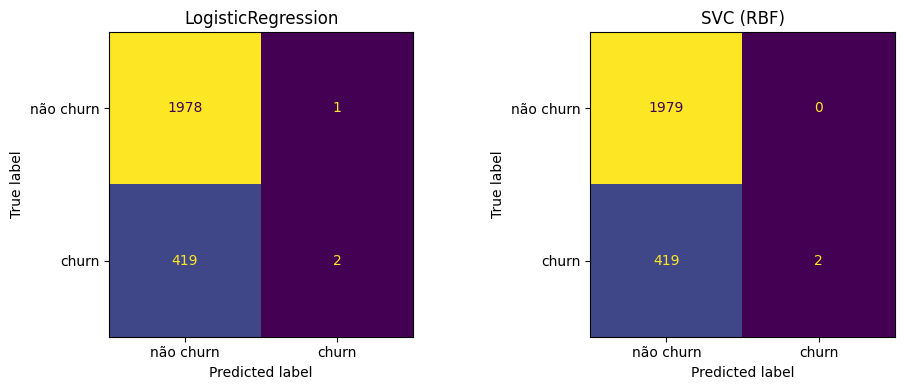

In [53]:
fig, eixos = plt.subplots(1, 2, figsize = (10, 4))

for eixo, (nome, modelo) in zip(eixos, modelos_churn.items()):
    ConfusionMatrixDisplay.from_estimator(
        modelo, X_test, y_test, display_labels = ["não churn", "churn"], colorbar = False, ax = eixo
    )
    eixo.set_title(nome)

plt.tight_layout()
plt.show()

Com o threshold padrão, as duas matrizes são praticamente iguais, ambos deixam passar 419 dos 421 cancelamentos e acertam apenas 2. A diferença está no ranking dos assinantes por risco, o AUC-ROC da regressão logística é de 0,6640, e o do SVC com kernel RBF, de 0,5482.

### 10.3 Escreva uma recomendação final em um bloco de texto intitulado DECISAO MODELO CHURN, justificando a escolha com base nas métricas comparadas e no custo de negócio de falsos negativos discutido no Exercício 1.

**Decição Modelo Churn**

| Modelo | TN | FP | FN | TP | Precisão | Recall | AUC-ROC (teste) | AUC (validação cruzada) |
|---|---|---|---|---|---|---|---|---|
| LogisticRegression | 1978 | 1 | 419 | 2 | 66,67% | 0,48% | 0,6640 | 0,6578 |
| SVC (RBF), C = 1 | 1979 | 0 | 419 | 2 | 100% | 0,48% | 0,5482 | 0,5629 |

- **Recomendação:** levar a `LogisticRegression` para produção.

- **Melhor ordenação do risco:** a regressão logística tem AUC-ROC bem maior, tanto no teste quanto na validação cruzada, e o resultado é consistente entre as duas avaliações. O SVC com kernel RBF, apesar de mais flexível, separa as classes só um pouco melhor que o acaso neste problema.
- **A precisão de 100% do SVC não é um ponto a favor:** ela se refere a apenas 2 alertas, o que não é uma amostra confiável, e os dois modelos têm o mesmo recall.
- **Custo do falso negativo:** como visto no Exercício 1, o erro mais caro é o assinante que cancela sem alerta, e com o threshold padrão, nenhum dos dois modelos resolve isso. Para reduzir esse custo, o caminho é baixar o threshold, como analisado no Exercício 2, em que a regressão logística chegou a 94,30% de recall com threshold 0.10. Isso só funciona bem se o modelo ordenar bem os assinantes, e é onde a regressão logística é superior. Com AUC próximo de 0,55, baixar o limiar do SVC traria um ganho de recall pequeno para o volume de alertas gerados.